# 01 — Image Classification and k-Nearest Neighbours

**CS231n Lecture 2.** The first real idea in the course: you cannot write down
what a cat *is*, so you stop trying and learn it from data instead.

What you'll build here, all in numpy:

| You write | Why it matters |
|---|---|
| `compute_distances_two_loops` | the honest, slow definition |
| `compute_distances_one_loop` | broadcasting replaces the inner loop |
| `compute_distances_no_loops` | the expand-the-square trick — ~100x faster |
| `predict_labels` | k-nearest voting, including the tie rule |
| `cross_validate_knn` | picking k without touching the test set |

**How this notebook works.** Cells marked `TODO` are yours. Fill them in, then
run the `grade(...)` cell underneath — it compares your function against a
reference on fixed inputs and prints a relative error. Anything you haven't
written yet falls back to the reference so the rest of the notebook still runs.
`show_solution(...)` reveals the reference when you want to compare, not copy.

In [1]:
import sys, os, time
sys.path.insert(0, os.path.abspath('.'))

import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

from cs231n_utils import (get_cifar10, CLASSES, rel_error, grade, show_solution,
                          use, show_images, plot_series, setup_plots,
                          plot_norm_balls, plot_distance_concentration, plot_knn_regions)

setup_plots()
np.random.seed(0)
print("numpy", np.__version__)

numpy 2.4.4


## 1. Why the data-driven approach

Write the function `is_cat(image) -> bool` using rules. You immediately hit the
six problems CS231n opens with, and every one of them changes the pixel values
completely while leaving the label alone:

- **viewpoint** — rotate the camera 30 degrees, every pixel moves
- **illumination** — same cat, different photons
- **deformation** — cats are famously non-rigid
- **occlusion** — a tail behind a couch is still a cat
- **background clutter** — a cat the colour of the carpet
- **intraclass variation** — a Sphynx and a Maine Coon

So the API changes shape. Instead of one function, you write two:

```python
def train(images, labels):     # ingest data, return a model
def predict(model, images):    # use the model to guess labels
```

That split — **train** and **predict** as separate steps — is the entire rest of
the course. Everything after this notebook just makes the model in the middle
better.

In [2]:
data = get_cifar10(num_train=5000, num_val=500, num_test=500, flatten=False,
                   subtract_mean=False)
X_train_img, y_train = data['X_train'], data['y_train']
X_test_img,  y_test  = data['X_test'],  data['y_test']

print("images are", X_train_img.shape, X_train_img.dtype, "in NCHW layout")
print("labels are", y_train.shape, "with values", np.unique(y_train))
print(y_train.shape)

train (5000, 3, 32, 32)  val (500, 3, 32, 32)  test (500, 3, 32, 32)
images are (5000, 3, 32, 32) float32 in NCHW layout
labels are (5000,) with values [0 1 2 3 4 5 6 7 8 9]
(5000,)


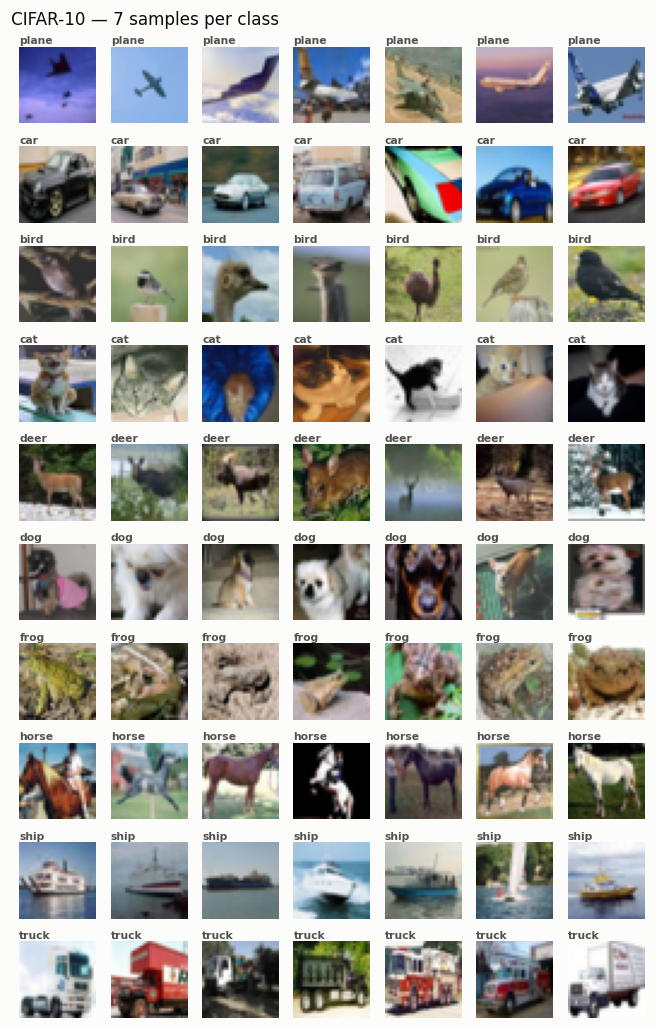

In [3]:
# Seven examples of each class. Look at how much within-class variation there is.
picks = np.concatenate([np.flatnonzero(y_train == c)[:7] for c in range(10)])

show_images(X_train_img[picks], labels=y_train[picks], class_names=CLASSES,
            ncols=7, title="CIFAR-10 — 7 samples per class", scale=1.0)
plt.show()

### Flatten to vectors

kNN and linear classifiers don't know an image is 2D. Each 32x32x3 image becomes
a single point in **3072-dimensional space**, and the whole method is "which
training points are nearby".

Hold on to that framing — it is why kNN fails later in this notebook.

In [4]:
data = get_cifar10(num_train=5000, num_val=500, num_test=500, flatten=True,
                   subtract_mean=False)
X_train, y_train = data['X_train'], data['y_train']
X_val,   y_val   = data['X_val'],   data['y_val']
X_test,  y_test  = data['X_test'],  data['y_test']

print("X_train", X_train.shape, "-> each image is a point in R^%d" % X_train.shape[1], y_train.shape)  

train (5000, 3072)  val (500, 3072)  test (500, 3072)
X_train (5000, 3072) -> each image is a point in R^3072 (5000,)


## 2. Nearest Neighbour

The laziest possible classifier:

- **train**: memorise the training set. O(1).
- **predict**: for each test image, find the closest training image, copy its label. O(N).

Note the complexity is *backwards* from what you want. Training is free and
prediction is expensive — in deployment you want the opposite. That alone
disqualifies kNN for real use, before we even talk about accuracy.

Two distance metrics:

$$ d_1(a,b) = \sum_p |a_p - b_p| \qquad \text{(L1, Manhattan)} $$

$$ d_2(a,b) = \sqrt{\sum_p (a_p - b_p)^2} \qquad \text{(L2, Euclidean)} $$

L1 depends on your choice of coordinate axes; L2 does not (it is rotation
invariant). If the individual dimensions carry specific meaning — "hours slept",
"salary" — L1 is often the better default. For raw pixels neither is
meaningful, which is the point of section 5.

### See the difference before you write the formula

Both metrics turn a pair of vectors into one number, but they disagree about
what "distance 1" looks like. Below, the **L2 ball** (blue) is the familiar
circle; the **L1 ball** (orange) is a diamond, because L1 only lets you move
along the axes one at a time — like walking city blocks instead of flying
straight.

For the point marked below, L2 is the straight-line arrow; L1 is the
axis-aligned staircase. Same endpoint, different notion of "how far".

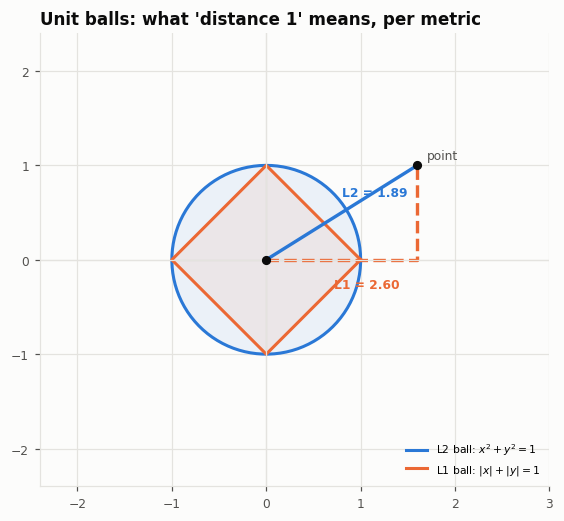

In [5]:
plot_norm_balls(point=(1.6, 1.0))
plt.show()

### TODO 1 — the two-loop version

Write the definition directly. `X` is `(num_test, D)`, `X_train` is
`(num_train, D)`. Return `dists` of shape `(num_test, num_train)` where
`dists[i, j]` is the **L2** distance between test image `i` and train image `j`.

Do not use `np.linalg.norm` — write the arithmetic out, you want the formula in
your fingers.

In [6]:
def compute_distances_two_loops(X, X_train):
    num_test, num_train = X.shape[0], X_train.shape[0]
    dists = np.zeros((num_test, num_train))
    for i in range(num_test):
        for j in range(num_train):
            dists[i,j] = np.sqrt(np.sum((X[i] - X_train[j])**2)) 
            # print(X.shape)
            # TODO: dists[i, j] = L2 distance between X[i] and X_train[j]
    return dists


In [7]:
grade('nb01', 'compute_distances_two_loops', compute_distances_two_loops)

[PASS] compute_distances_two_loops  case 1/2  out  rel error 0.000e+00
[PASS] compute_distances_two_loops  case 2/2  out  rel error 0.000e+00
--> compute_distances_two_loops looks correct.


True

### TODO 2 — one loop

Kill the inner loop with broadcasting. Inside the `i` loop you have `X[i]` of
shape `(D,)` and `X_train` of shape `(num_train, D)`.

**Predict before you run it:** what shape is `X_train - X[i]`? Which axis do you
sum over to get one number per training image?

In [8]:
def compute_distances_one_loop(X, X_train):
    num_test = X.shape[0]
    dists = np.zeros((num_test, X_train.shape[0]))
    for i in range(num_test):
        # dists[i] = np.sqrt(np.sum((X[i] - X_train[i])**2, axis=1))
        dists[i] = np.sqrt(np.sum((X[i] - X_train)**2, axis=1))
    print(dists.shape)    
    return dists

In [9]:
grade('nb01', 'compute_distances_one_loop', compute_distances_one_loop)

(7, 11)
(3, 4)
[PASS] compute_distances_one_loop  case 1/2  out  rel error 0.000e+00
[PASS] compute_distances_one_loop  case 2/2  out  rel error 0.000e+00
--> compute_distances_one_loop looks correct.


True

### TODO 3 — no loops (the one that matters)

You cannot broadcast your way out of the outer loop: `X` is `(num_test, D)` and
`X_train` is `(num_train, D)`, and materialising the `(num_test, num_train, D)`
difference tensor would be 500 x 5000 x 3072 x 8 bytes, about **61 GB**. Try it
and your machine dies.

The way out is algebra, not numpy. Expand the square:

$$ \|a - b\|^2 = (a-b)\cdot(a-b) = \|a\|^2 - 2\,a\cdot b + \|b\|^2 $$

Every term on the right is cheap:

| Term | Shape | How |
|---|---|---|
| $\|a\|^2$ | `(num_test, 1)` | `np.sum(X**2, axis=1)[:, None]` |
| $\|b\|^2$ | `(1, num_train)` | `np.sum(X_train**2, axis=1)[None, :]` |
| $a \cdot b$ | `(num_test, num_train)` | one matrix multiply |

Broadcasting adds the column vector and the row vector into the full matrix for
free. **The matrix multiply is the whole trick** — it hands the work to BLAS,
which is where the 100x comes from.

One trap: floating-point cancellation can make a genuinely-zero squared distance
come out as `-1e-13`, and `np.sqrt` of that is `nan`. Clamp at zero.

In [10]:
def compute_distances_no_loops(X, X_train):
    # TODO: expand the square. No python loops, no (num_test, num_train, D) array.
    # Remember to clamp negatives before sqrt.
    X_square = np.sum(X**2, axis=1)[:,None]
    Xtrain_square = np.sum(X_train**2 , axis = 1)[None,:]
    ab = np.dot(X , X_train.T)
    return np.sqrt(X_square + Xtrain_square - 2*ab)
    


# def compute_distances_no_loops(X, X_train):
#     X_square = np.sum(X**2, axis=1)[:, None]          # (num_test, 1)
#     Xtrain_square = np.sum(X_train**2, axis=1)[None, :]  # (1, num_train)
#     ab = np.dot(X, X_train.T)                           # (num_test, num_train)
#     dists_sq = X_square + Xtrain_square - 2*ab
#     return np.sqrt(np.maximum(dists_sq, 0))    

In [11]:
grade('nb01', 'compute_distances_no_loops', compute_distances_no_loops)
show_solution('nb01', 'compute_distances_no_loops')


[PASS] compute_distances_no_loops  case 1/2  out  rel error 0.000e+00
[PASS] compute_distances_no_loops  case 2/2  out  rel error 0.000e+00
--> compute_distances_no_loops looks correct.
def compute_distances_no_loops(X, X_train):
    # ||a - b||^2 = ||a||^2 - 2 a.b + ||b||^2
    test_sq = np.sum(X ** 2, axis=1)[:, np.newaxis]        # (num_test, 1)
    train_sq = np.sum(X_train ** 2, axis=1)[np.newaxis, :]  # (1, num_train)
    cross = X.dot(X_train.T)                                # (num_test, num_train)
    sq = test_sq + train_sq - 2 * cross
    # floating point can push exact zeros a hair negative
    return np.sqrt(np.maximum(sq, 0))



### How much did that buy you?

In [12]:
d2l = use('nb01', 'compute_distances_two_loops', compute_distances_two_loops)
d1l = use('nb01', 'compute_distances_one_loop',  compute_distances_one_loop)
d0l = use('nb01', 'compute_distances_no_loops',  compute_distances_no_loops)

Xs, Xts = X_test[:200], X_train[:2000]
timings = {}
for name, fn in [('two loops', d2l), ('one loop', d1l), ('no loops', d0l)]:
    t0 = time.time()
    D = fn(Xs, Xts)
    timings[name] = time.time() - t0
    print("%-10s %6.2f s" % (name, timings[name]))

print("\nspeedup, two loops -> no loops: %.0fx"
      % (timings['two loops'] / max(timings['no loops'], 1e-9)))

# and they must agree, or the fast one is just fast and wrong
print("agreement (two vs no loops): rel error %.2e" % rel_error(d2l(Xs, Xts), d0l(Xs, Xts)))

(7, 11)
(3, 4)
two loops    2.65 s
(200, 2000)
one loop     6.48 s
no loops     0.04 s

speedup, two loops -> no loops: 63x
agreement (two vs no loops): rel error 0.00e+00


> **The habit to steal:** every time you vectorise something, diff it against
> the slow version on a small input. A fast wrong answer is worse than a slow
> right one, and this failure mode is silent.

**Look closely at the one-loop timing.** On many machines it comes out *slower
than the two-loop version*. That is not a mistake, and it is the more useful
lesson here.

Both do the same arithmetic. But the one-loop version allocates a fresh
`(num_train, D)` temporary on every iteration — at 2000 x 3072 float64 that is
49 MB per test image, streamed through memory and thrown away. The two-loop
version works on one `(D,)` row at a time, which stays in cache.

So "vectorised" does not mean "fast". What made the no-loop version fast was not
deleting a `for` statement — it was **restructuring the computation into a single
large matrix multiply** that BLAS executes with blocking, multithreading and
cache reuse. Removing a loop only helps when it hands work to something better
at doing it.

### TODO 4 — L1 distance

Write the L1 version. **Before you write it:** can you use the same
expand-the-square trick? Answer in a comment, then implement.

In [13]:
def compute_distances_l1(X, X_train):
    # Q: does the ||a||^2 - 2ab + ||b||^2 trick work for L1? Why / why not?
    # A:
    num_test = X.shape[0]
    dists = np.zeros((num_test, X_train.shape[0]))
    for i in range(num_test):
        dists[i] = np.sum(np.abs(X[i] - X_train),axis = 1)    
    print(dists.shape)    
    return dists

In [14]:
grade('nb01', 'compute_distances_l1', compute_distances_l1)

(7, 11)
(3, 4)
[PASS] compute_distances_l1  case 1/2  out  rel error 0.000e+00
[PASS] compute_distances_l1  case 2/2  out  rel error 0.000e+00
--> compute_distances_l1 looks correct.


True

## 3. From distances to predictions

`k = 1` copies the nearest neighbour's label. Larger `k` takes a **majority vote**
over the k nearest, which smooths the decision boundary and makes the classifier
less sensitive to a single weird training image.

Two details people get wrong:

- **argsort, not argmin.** You need the k smallest, in order.
- **ties.** With k=5 and labels `[3, 3, 7, 7, 1]`, what wins? Convention here:
  `np.bincount` then `np.argmax`, which picks the **smallest label** among tied
  counts. It is arbitrary, but it has to be *decided* — otherwise your accuracy
  quietly depends on row order.

In [15]:
def predict_labels(dists, y_train, k=1):
    num_test = dists.shape[0]
    y_pred = np.zeros(num_test, dtype=np.int64)
    for i in range(num_test):
        # TODO
        #  1. indices of the k smallest entries of dists[i]
        #  2. their labels from y_train
        #  3. the most common label (np.bincount + np.argmax)
        values = y_train[np.argsort(dists[i])[:k]]
        y_pred[i] = np.argmax(np.bincount(values))
        pass
    return y_pred

In [16]:
grade('nb01', 'predict_labels', predict_labels)

[PASS] predict_labels  case 1/2  out  rel error 0.000e+00
[PASS] predict_labels  case 2/2  out  rel error 0.000e+00
--> predict_labels looks correct.


True

In [17]:
predict = use('nb01', 'predict_labels', predict_labels)

dists_val = d0l(X_val, X_train)
for k in [1, 3, 5, 10]:
    acc = np.mean(predict(dists_val, y_train, k=k) == y_val)
    print("k = %-3d  val accuracy %.3f" % (k, acc))
print("\nrandom guessing would be 0.100")

k = 1    val accuracy 0.278
k = 3    val accuracy 0.252
k = 5    val accuracy 0.256
k = 10   val accuracy 0.276

random guessing would be 0.100


### See the vote itself, in a dimension you can look at

`X_train` lives in R^3072, far too many dimensions to plot. But the voting rule
is exactly the same in R^2, so build three toy 2D classes and watch `k`
literally carve up the plane. Each region is "every point whose k nearest
training points vote for this class" — this is the geometric object that
`predict_labels` is silently building over all 3072 pixel dimensions above.

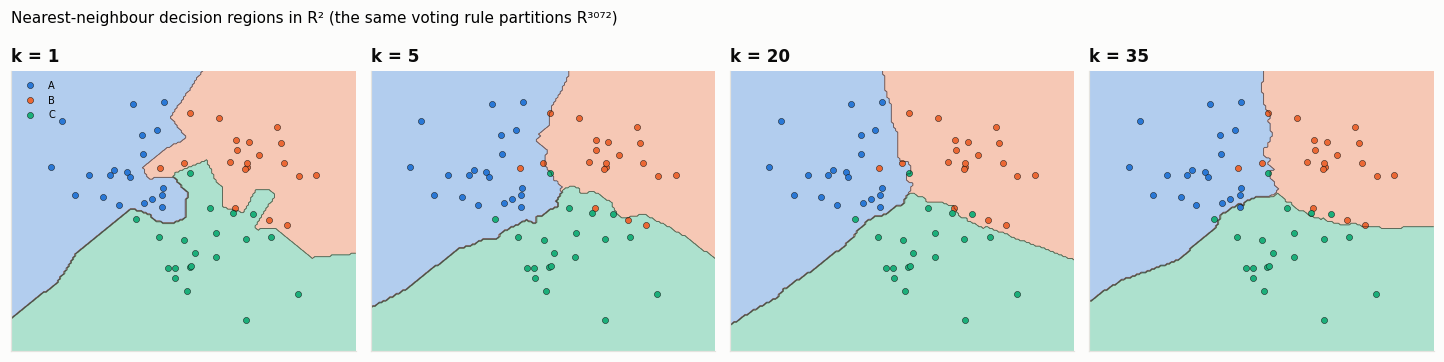

In [24]:
toy_rng = np.random.RandomState(2)
centers = np.array([[-1.8, 1.3], [1.8, 1.5], [0.0, -1.8]])
toy_names = ['A', 'B', 'C']
X_toy = np.concatenate([c + 1.15 * toy_rng.randn(20, 2) for c in centers])
y_toy = np.concatenate([np.full(20, i) for i in range(3)])

plot_knn_regions(X_toy, y_toy, d0l, predict, k_list=[1, 5, 20, 35],
                 class_names=toy_names)
plt.show()

`k=1` gives a jagged boundary that chases every single training point,
including noise — a Voronoi diagram of the training set. As `k` grows the
boundary smooths, because a majority vote among more neighbours washes out any
one point's idiosyncrasy. Push `k` too far (try 15 vs. the full training set
size) and the regions start ignoring structure entirely, voting for whichever
class simply has more points nearby. That tension — jagged-and-sensitive vs.
smooth-and-blind — is exactly what the cross-validation curve below is
searching over, just with 3072 axes instead of 2.

## 4. Cross-validation — choosing k without cheating

`k` is a **hyperparameter**: you don't learn it from the data, you choose it. The
rule that matters more than the technique:

> **You get to touch the test set once, at the very end, and you report that
> number.** If you tune anything against test accuracy, your test set has
> silently become a validation set and your reported number is optimistic.

With plenty of data: split train / val / test, tune on val. With little data,
**k-fold cross-validation** — chop the training set into `num_folds` pieces, and
for each fold train on the rest and validate on it. Average the folds.

One subtlety worth internalising: compute the distance matrix **once per fold**,
then reuse it for every `k`. The distances do not depend on `k` — only the
voting does. Getting this wrong makes cross-validation `len(k_choices)`x slower
for no reason.

In [29]:
def cross_validate_knn(X_train, y_train, k_choices, num_folds=5):
    """Return {k: [accuracy on each fold]}, using the same folds for every k."""
    X_folds = np.array_split(X_train, num_folds)
    y_folds = np.array_split(y_train, num_folds)
    accuracies = {k: [] for k in k_choices}
    for f in range(num_folds):
        # TODO
        #  - fold f is validation; concatenate the others for training
        #  - ONE distance matrix for this fold
        #  - then loop over k_choices and vote
        X_tr = np.concatenate(X_folds[:f] + X_folds[f+1:])
        Y_tr = np.concatenate(y_folds[:f] + y_folds[f+1:])
        dists = compute_distances_no_loops(X_folds[f], X_tr)
        for k in k_choices:
            pred = predict_labels(dists, Y_tr, k=k)
            accuracies[k].append(np.mean(pred == y_folds[f]))
            
        pass
    return accuracies

In [30]:
grade('nb01', 'cross_validate_knn', cross_validate_knn)

[PASS] cross_validate_knn  case 1/1  out[1]  rel error 0.000e+00
[PASS] cross_validate_knn  case 1/1  out[3]  rel error 0.000e+00
[PASS] cross_validate_knn  case 1/1  out[5]  rel error 0.000e+00
--> cross_validate_knn looks correct.


True

1.1 s


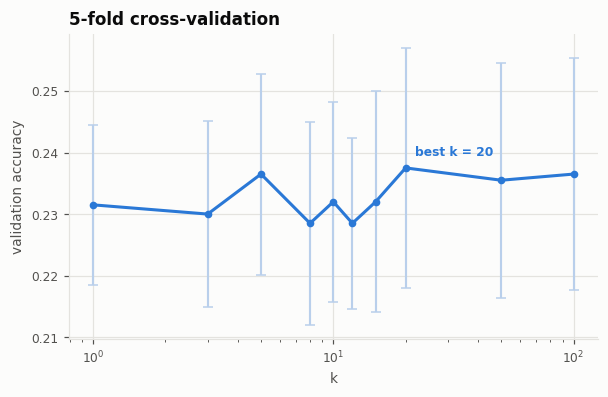

best k = 20  mean acc 0.237


In [31]:
cv = use('nb01', 'cross_validate_knn', cross_validate_knn)

k_choices = [1, 3, 5, 8, 10, 12, 15, 20, 50, 100]
t0 = time.time()
acc = cv(X_train[:2000], y_train[:2000], k_choices, num_folds=5)
print("%.1f s" % (time.time() - t0))

means = np.array([np.mean(acc[k]) for k in k_choices])
stds  = np.array([np.std(acc[k])  for k in k_choices])

fig, ax = plt.subplots(figsize=(6.2, 3.6))
ax.errorbar(k_choices, means, yerr=stds, color='#2a78d6', ecolor='#b9cfeb',
            elinewidth=1.4, capsize=3, marker='o', markersize=4)
ax.set_title("5-fold cross-validation")
ax.set_xlabel("k")
ax.set_ylabel("validation accuracy")
ax.set_xscale('log')
ax.set_axisbelow(True)
best_k = k_choices[int(np.argmax(means))]
ax.annotate("best k = %d" % best_k, xy=(best_k, means.max()),
            xytext=(6, 8), textcoords='offset points', fontsize=8,
            color='#2a78d6', weight='semibold')
plt.show()
print("best k =", best_k, " mean acc %.3f" % means.max())

In [32]:
# The single permitted look at the test set.
dists_test = d0l(X_test, X_train)
test_acc = np.mean(predict(dists_test, y_train, k=best_k) == y_test)
print("TEST accuracy with k=%d: %.3f" % (best_k, test_acc))

TEST accuracy with k=20: 0.286


## 5. Blind spot — why nobody uses kNN on images

kNN tops out under 30% here — better than the 10% of guessing, nowhere near
usable. Here is the actual reason, and it is more interesting than "kNN is
weak".

**Pixel-space L2 distance is nearly uncorrelated with semantic similarity.**

The demo below takes one image and produces three corruptions — shifted, tinted,
and partially blacked out — with the perturbation magnitudes tuned so all three
sit at roughly the same L2 distance from the original. One of them a human would
barely notice; one destroys a chunk of the image. The metric cannot tell them
apart.

original           L2 from original:      0.0
shifted 3px        L2 from original:   1234.9
tinted +39         L2 from original:   1234.9
masked 8x8         L2 from original:   1165.2


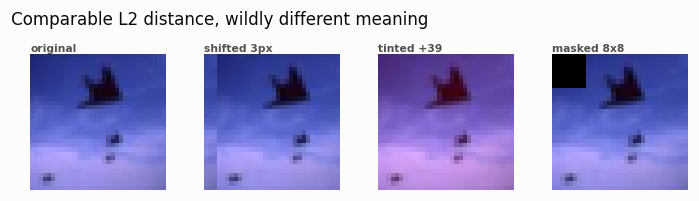

In [33]:
base = X_train_img[7].transpose(1, 2, 0).astype(np.float64)   # HWC, 0..255

def l2(a, b):
    return np.sqrt(np.sum((a - b) ** 2))

shifted = np.roll(base, 3, axis=1)                  # translate 3 px right
target = l2(base, shifted)                          # match this distance

# uniform red-channel tint of the magnitude that reproduces `target`
delta = target / np.sqrt(base[:, :, 0].size)
tinted = base.copy()
tinted[:, :, 0] = np.clip(base[:, :, 0] + delta, 0, 255)

# black square whose removed energy is as close to `target` as an integer
# side length allows -- zeroing a corner removes exactly its own pixel energy
side_errs = [(abs(np.sqrt(np.sum(base[:s, :s, :] ** 2)) - target), s)
             for s in range(1, 33)]
side = min(side_errs)[1]
masked = base.copy()
masked[:side, :side, :] = 0

variants = [base, shifted, tinted, masked]
names = ['original', 'shifted 3px', 'tinted +%.0f' % delta, 'masked %dx%d' % (side, side)]
for img, nm in zip(variants, names):
    print("%-18s L2 from original: %8.1f" % (nm, l2(base, img)))

show_images(np.stack(variants), labels=np.arange(4), class_names=names, ncols=4,
            title="Comparable L2 distance, wildly different meaning", scale=1.9)
plt.show()

Three corruptions at a comparable distance, ranked in an order that has nothing
to do with how a person would rank them. A 3-pixel shift is semantically *free*
and metrically expensive; that is a metric problem, not a classifier problem.

There is a second, deeper reason: **the curse of dimensionality.** kNN needs the
training points to densely cover the space. In 1D you need ~4 points; in 2D ~4^2;
in 3072 dimensions you would need 4^3072 — more than the number of atoms in the
universe by an absurd margin. Your 5000 CIFAR images are not "covering"
R^3072; they are isolated specks.

So the fix is not a better k. The fix is to **stop comparing raw pixels** and
learn a representation in which distance means something. That is the rest of
the course.

### The curse of dimensionality, made visible

The claim above — "4^3072 points wouldn't cover the space" — is abstract.
Here is the concrete symptom it causes. Sample random points and a random
query in R^d, and look at the ratio `(farthest - nearest) / nearest`. In low
dimensions "nearest neighbour" is a meaningful idea: some points really are
much closer than others. Watch what happens to that gap as `d` grows.

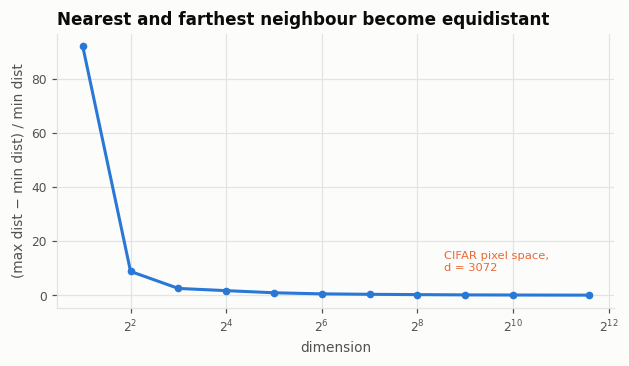

In [34]:
plot_distance_concentration()
plt.show()

By a few hundred dimensions the gap between your nearest and farthest
"neighbour" has nearly vanished — every point is roughly the same distance
away. "Nearest neighbour" stops being a meaningful question well before you
reach 3072. This is a property of high-dimensional space itself, independent
of what the pixels mean; the colour-matching failure above is the second,
unrelated reason kNN struggles here.

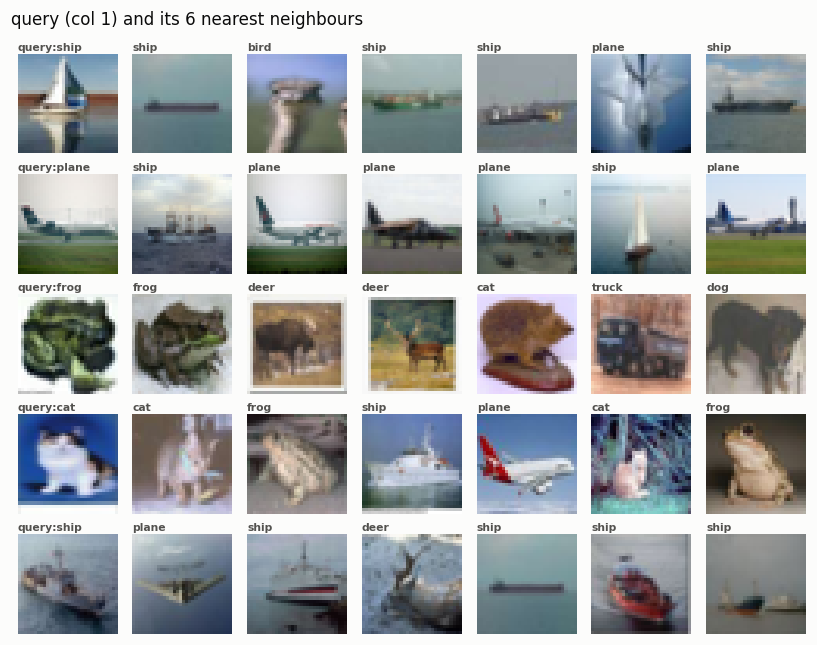

In [35]:
# Worth seeing directly: what the nearest neighbours of a few test images are.
q = np.arange(5)
nn_idx = np.argsort(dists_test[q], axis=1)[:, :6]

rows, row_lbl = [], []
for r, qi in enumerate(q):
    rows.append(X_test_img[qi])
    row_lbl.append("query:" + CLASSES[y_test[qi]])
    for j in nn_idx[r]:
        rows.append(X_train_img[j])
        row_lbl.append(CLASSES[y_train[j]])

show_images(np.stack(rows), labels=np.arange(len(rows)), class_names=row_lbl,
            ncols=7, title="query (col 1) and its 6 nearest neighbours", scale=1.25)
plt.show()

Look at the colour statistics rather than the objects. The neighbours tend to
share the *background* — blue sky, green field, dark frame — regardless of what
the subject is. kNN on pixels is, to a first approximation, a background-colour
matcher.

## 6. Recap — answer these without scrolling up

1. Why is kNN's train/predict cost profile the wrong way round for deployment?
2. Write the expansion of $\|a-b\|^2$. Which term becomes the matrix multiply?
3. Why does that trick not work for L1?
4. In `compute_distances_no_loops`, why clamp before `sqrt`?
5. Why compute the distance matrix once per *fold* instead of once per *(fold, k)*?
6. What exactly goes wrong if you pick `k` using test accuracy?
7. Give two independent reasons pixel-L2 is a bad similarity measure for images.

In [ ]:
# Reveal any reference implementation when you want to compare:
# show_solution('nb01', 'compute_distances_no_loops')
# show_solution('nb01', 'predict_labels')
# show_solution('nb01', 'cross_validate_knn')